In [2]:
import numpy as np
from sentence_transformers import SentenceTransformer

sentences = [
    "Eu ainda acho que isso é uma péssima ideia",
    "Aquele corredor não devia estar aberto",
    "Tem alguma coisa errada ali",
    "Você também sentiu isso?",
    "Parece que estamos sendo observados",
    "Talvez seja só impressão",
    "Mesmo assim, melhor não arriscar",
    "A gente devia voltar",
    "Mas agora já estamos aqui",
    "Só vamos dar uma olhada rápida",
    "Promete que é só uma olhada?",
    "Prometo",
    "Então vamos logo",
    "Essa escola guarda muitos segredos",
    "Principalmente nos lugares proibidos",
    "E geralmente tem um motivo pra serem proibidos",
    "Você acha que alguém está escondendo algo?",
    "Não duvido",
    "Hogwarts sempre teve mistérios",
    "E a gente sempre acaba se metendo neles",
    "Talvez a gente devesse focar mais nas aulas",
    "Tipo a de poções amanhã",
    "Verdade, eu nem comecei o dever",
    "Nem eu",
    "O professor não vai gostar nada disso",
    "Ele nunca gosta de nada",
    "Principalmente quando a gente erra",
    "E eu sempre erro naquela matéria",
    "Talvez seja só falta de prática",
    "Ou falta de atenção",
    "Ou falta de interesse",
    "Você só pensa em sair explorando tudo",
    "E você só pensa em estudar",
    "Alguém precisa equilibrar isso",
    "Falando em equilibrar, você já jantou?",
    "Agora que você falou, não",
    "A gente saiu antes do jantar",
    "Isso explica porque eu estou com fome",
    "Eu também estou começando a sentir",
    "A cozinha ainda deve estar aberta",
    "Será que dá pra ir até lá sem ser visto?",
    "Depois do que aconteceu hoje?",
    "Provavelmente não",
    "Mas vale a tentativa",
    "Se tiver torta eu topo qualquer risco",
    "Você só pensa em comida mesmo",
    "Depois de quase morrer, eu mereço",
    "Pensando bem, eu também mereço",
    "Então vamos pra cozinha",
    "Só dessa vez",
    "E amanhã a gente resolve o resto"
]

sentences_e5 = [f"passage: {s}" for s in sentences]
model = SentenceTransformer('intfloat/multilingual-e5-base')

S = model.encode(sentences_e5)

print("\nEmbeddings (S):")
print(S.shape)
print(S)

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 44050.37it/s]
XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(51, 768)
[[-0.01059808  0.03678442 -0.02576697 ... -0.04533979 -0.02788712
  -0.00101658]
 [ 0.00600717  0.01689685 -0.03228227 ... -0.05023767 -0.04344219
   0.0385293 ]
 [-0.00040908  0.0071517  -0.03099364 ... -0.05064199 -0.04966632
   0.03481925]
 ...
 [ 0.01631249  0.01292337 -0.03325099 ... -0.05019362 -0.04184243
   0.04204202]
 [ 0.01591042  0.02118906 -0.0233267  ... -0.01528849 -0.03247431
   0.01031655]
 [ 0.00384802  0.01651978 -0.02127534 ... -0.04125264 -0.03524356
   0.01116938]]


In [3]:
S = model.encode(sentences_e5, normalize_embeddings=False)

scores = np.dot(S, S.T)

n = len(sentences)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i:
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.88360041 0.         0.         ... 0.         0.         0.        ]
 [0.86499405 0.86492813 0.         ... 0.         0.         0.        ]
 ...
 [0.83366305 0.83872324 0.83866143 ... 0.         0.         0.        ]
 [0.86114347 0.85679674 0.84585154 ... 0.86806047 0.         0.        ]
 [0.83903432 0.83910424 0.8287946  ... 0.87904    0.86128575 0.        ]]


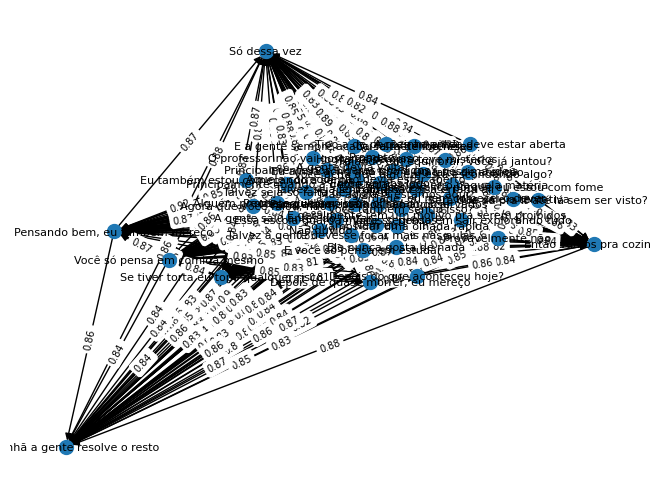

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences_e5):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:
            G.add_edge(j, i, weight=weight)

pos = nx.spring_layout(G)

nx.draw(G, pos, node_size=100)

node_labels = {i: s for i, s in enumerate(sentences)}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)

edge_labels = {k: round(v, 2) for k, v in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()

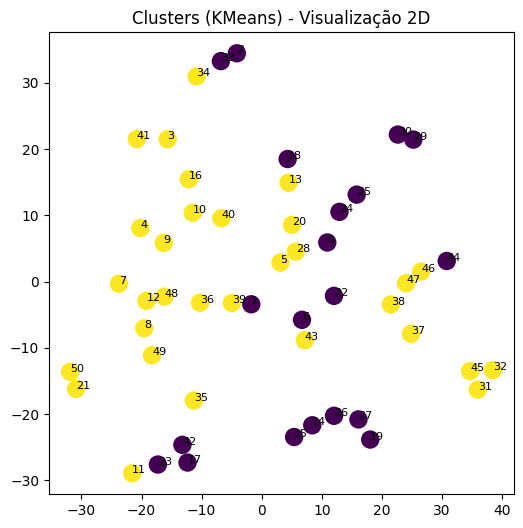

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

S_norm = normalize(S)

kmeans = KMeans(n_clusters=2, random_state=0)
labels = kmeans.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)


plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=150)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title("Clusters (KMeans) - Visualização 2D")
plt.show()

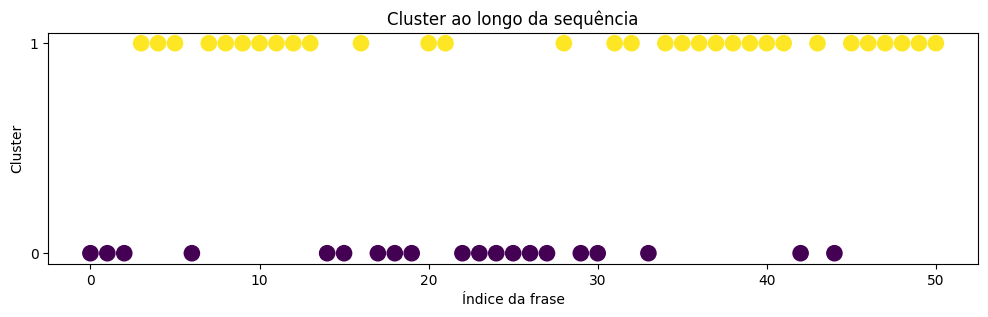

In [6]:
plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks([0,1])
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Cluster ao longo da sequência")

plt.show()

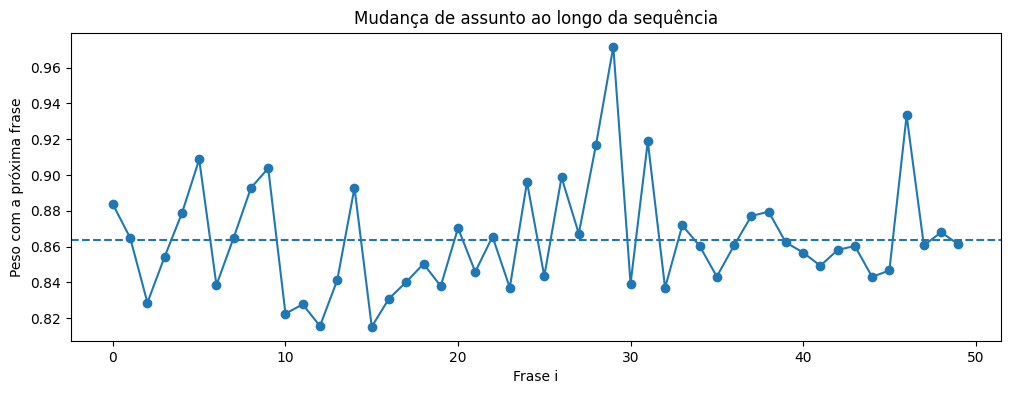

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

S_norm = normalize(S)

weights = np.array([
    cosine_similarity(S_norm[i].reshape(1, -1), S_norm[i+1].reshape(1, -1))[0, 0]
    for i in range(len(S_norm) - 1)
])

plt.figure(figsize=(12, 4))
plt.plot(weights, marker='o')
plt.axhline(np.mean(weights), linestyle='--')
plt.xlabel("Frase i")
plt.ylabel("Peso com a próxima frase")
plt.title("Mudança de assunto ao longo da sequência")
plt.show()

In [8]:
def cosine(a, b):
    return cosine_similarity(a.reshape(1, -1), b.reshape(1, -1))[0, 0]

k = 3  

pivot_scores = []

for i in range(k, len(S_norm) - k):
    prev_ctx = S_norm[i-k:i].mean(axis=0)
    next_ctx = S_norm[i+1:i+k+1].mean(axis=0)
    score = 1 - cosine(prev_ctx, next_ctx)
    pivot_scores.append((i, score))

pivot_scores.sort(key=lambda x: x[1], reverse=True)

print("Frases mais relevantes para mudança de rumo:")
for i, score in pivot_scores[:5]:
    print(f"\nÍndice {i} | score = {score:.4f}")
    print(sentences[i])

Frases mais relevantes para mudança de rumo:

Índice 12 | score = 0.0911
Então vamos logo

Índice 31 | score = 0.0811
Você só pensa em sair explorando tudo

Índice 39 | score = 0.0799
A cozinha ainda deve estar aberta

Índice 13 | score = 0.0789
Essa escola guarda muitos segredos

Índice 40 | score = 0.0745
Será que dá pra ir até lá sem ser visto?
